# Development

In [ ]:
SERIES_COLOR = classifiacation_palette[4]


def load_plot_data(data_dir):
    """Load the three CSV files and associated metadata."""
    data_dir = Path(data_dir)

    with open(data_dir / "metadata.json", encoding="utf-8") as file:
        metadata = json.load(file)

    heatmap = pd.read_csv(
        data_dir / "reflectivity_deviation_heatmap.csv"
    )
    anomaly = pd.read_csv(
        data_dir / "sedimentation_anomaly.csv"
    )
    correlation = pd.read_csv(
        data_dir / "peak_ice_fraction_correlation.csv"
    )

    return metadata, heatmap, anomaly, correlation


def reproduce_plot(
    data_dir,
    output_file,
    figure_label=None,
    series_color=SERIES_COLOR,
):
    metadata, heatmap, anomaly, correlation = load_plot_data(data_dir)

    settings = metadata["settings"]
    confidence_percent = 100 * settings["confidence_level"]

    # Use metadata order rather than relying on pivot sorting
    rel_times_min = np.asarray(settings["rel_times_min"], dtype=int)

    # Preserve the vertical-level order found in the saved CSV
    level_labels = heatmap["vertical_level"].drop_duplicates().tolist()

    heatmap_matrix = (
        heatmap
        .pivot(
            index="vertical_level",
            columns="rel_time_min",
            values="reflectivity_deviation_dbz",
        )
        .reindex(index=level_labels, columns=rel_times_min)
        .to_numpy()
    )

    # --------------------------------------------------------------
    # Figure layout
    # --------------------------------------------------------------
    fig = plt.figure(
        figsize=(5.501, 4),
        constrained_layout=True,
    )

    gs = gridspec.GridSpec(
        3,
        3,
        height_ratios=[1, 1, 1],
        width_ratios=[1, 1, 0.05],
        figure=fig,
    )

    ax_corr = fig.add_subplot(gs[0, :2])
    ax_heat = fig.add_subplot(gs[1, :2])
    ax_top_cb = fig.add_subplot(gs[1, 2])
    ax_anom = fig.add_subplot(gs[2, :2])

    # --------------------------------------------------------------
    # 1. Correlation panel
    # --------------------------------------------------------------
    corr_time = correlation["rel_time_min"].to_numpy()
    corr_value = correlation["corr_with_peak"].to_numpy()
    corr_ci_low = correlation["ci_low"].to_numpy()
    corr_ci_high = correlation["ci_high"].to_numpy()

    ax_corr.plot(
        corr_time,
        corr_value,
        marker="o",
        markersize=3,
        linewidth=1,
        zorder=3,
        color=series_color,
    )

    ax_corr.fill_between(
        corr_time,
        corr_ci_low,
        corr_ci_high,
        alpha=0.25,
        label=f"{confidence_percent:g}% bootstrap CI",
        zorder=2,
        color=series_color,
    )

    ax_corr.axhline(
        0,
        color="k",
        linewidth=1,
        zorder=4,
    )

    ax_corr.axhspan(
        -0.1,
        0.1,
        facecolor="none",
        edgecolor="0.65",
        hatch="/////",
        linewidth=0,
        zorder=0,
        label="Below 0.1",
    )

    xmin = np.nanmin(corr_time)
    xmax = np.nanmax(corr_time)

    xticks = np.arange(
        np.floor(xmin / 15) * 15,
        np.ceil(xmax / 15) * 15 + 15,
        15,
    )

    ax_corr.set_xticks(xticks)
    ax_corr.set_xlim(-45 - 7.5, 45 + 7.5)
    ax_corr.set_ylim(-0.1, 1.05)

    ax_corr.set_xlabel("Time relative to glaciation peak [min]")
    ax_corr.set_ylabel("Correlation with\n peak IF")
    ax_corr.set_title("Correlation with peak ice fraction")

    ax_corr.grid(alpha=0.3)
    ax_corr.legend()

    # --------------------------------------------------------------
    # 2. Heatmap panel
    # --------------------------------------------------------------
    image = ax_heat.imshow(
        heatmap_matrix,
        aspect="auto",
        cmap=cm.vik,
        norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3),
        origin="upper",
    )

    ax_heat.set_xticks(np.arange(len(rel_times_min)))
    ax_heat.set_xticklabels(rel_times_min)

    ax_heat.set_yticks(np.arange(len(level_labels)))
    ax_heat.set_yticklabels(level_labels)

    ax_heat.set_xlabel("Time relative to glaciation peak [min]")
    ax_heat.set_ylabel("Vertical level")
    # ax_heat.set_title(
    #     "Radar reflectivity deviation from level mean"
    # )

    colorbar = fig.colorbar(image, cax=ax_top_cb)
    colorbar.set_label("Deviation [dBZ]")
    colorbar.set_ticks([-3, -1.5, 0, 1.5, 3])

    # Hatch the -45 and +45 minute columns
    for selected_time in (-45, 45):
        matching_indices = np.where(
            rel_times_min == selected_time
        )[0]

        for index in matching_indices:
            ax_heat.axvspan(
                index - 0.5,
                index + 0.5,
                facecolor="none",
                edgecolor="0.3",
                hatch="////",
                linewidth=0,
                zorder=5,
            )

    # --------------------------------------------------------------
    # 3. Sedimentation anomaly panel
    # --------------------------------------------------------------
    anomaly_time = anomaly["rel_time_min"].to_numpy()
    anomaly_value = anomaly[
        "sedimentation_anomaly_dbz"
    ].to_numpy()
    anomaly_ci_low = anomaly["ci_low_dbz"].to_numpy()
    anomaly_ci_high = anomaly["ci_high_dbz"].to_numpy()

    yerr = np.vstack([
        np.maximum(anomaly_value - anomaly_ci_low, 0),
        np.maximum(anomaly_ci_high - anomaly_value, 0),
    ])

    ax_anom.errorbar(
        anomaly_time,
        anomaly_value,
        yerr=yerr,
        marker="o",
        linewidth=2,
        markersize=4,
        capsize=4,
        label=f"{confidence_percent:g}% bootstrap CI",
        color=series_color,
    )

    ax_anom.axhline(
        0,
        color="k",
        linewidth=1,
        alpha=0.5,
    )

    ax_anom.set_xticks(rel_times_min)
    ax_anom.set_xlim(-45 - 7.5, 45 + 7.5)

    ax_anom.set_ylim(-6, 6)
    ax_anom.set_yticks(np.arange(-6, 7, 3))

    ax_anom.set_xlabel(
        "Time relative to glaciation peak [min]"
    )
    ax_anom.set_ylabel("Sedimentation anomaly [dBZ]")
    ax_anom.set_title("Sedimentation anomaly")
    ax_anom.legend(loc="upper right")

    # Optional label identifying model or observations
    if figure_label:
        fig.suptitle(figure_label)

    output_file = Path(output_file)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_file,
        format=output_file.suffix.lstrip("."),
        dpi=300,
        bbox_inches="tight",
    )

    return fig

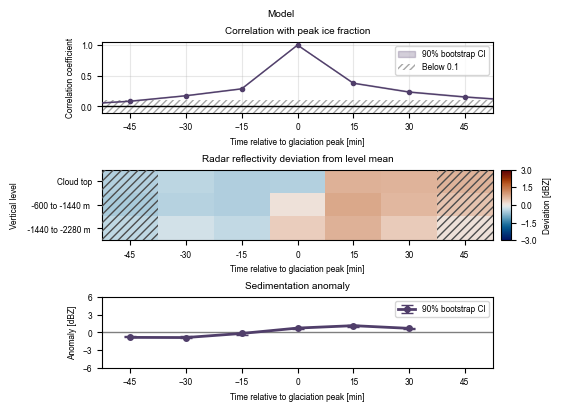

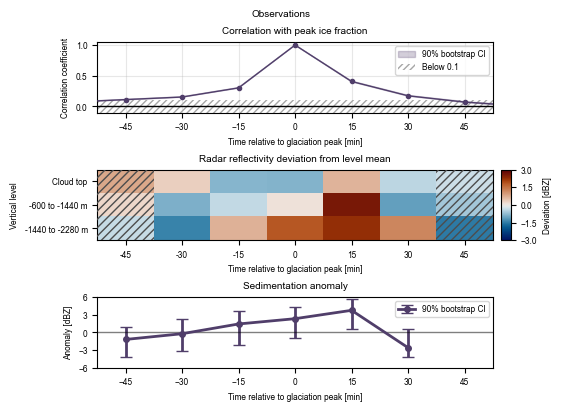

In [ ]:
base_dir = Path(
    "/Volumes/University_stuff/Code_Projects/MSGI/plotting/"
    "Publication_figures/data"
)

fig_model = reproduce_plot(
    data_dir=base_dir / "model",
    output_file=base_dir / "model_figure.pdf",
    figure_label="Model",
)

fig_observations = reproduce_plot(
    data_dir=base_dir / "observations",
    output_file=base_dir / "observations_figure.pdf",
    figure_label="Observations",
)

plt.show()